1) Load the dataset,
2) Features = A, B, C, D - Target = E (binary classifier)
3) Logistics Regression, Naive Bayes, KNN, SVM
4) Accuracies for all the models.
5) Which model is best. Apply GridSearchCV
6) Do hyperparameter tuning.
7) Again training the model based on best parametsrs

In [1]:
import numpy as np
import pandas as pd
import matplotlib as plt
import seaborn as sns

data = pd.read_csv(r"D:\NumPy\Social_Network_Ads.csv.xls - Social_Network_Ads.csv.xls.csv")
data

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


In [2]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
le = LabelEncoder()
data["Gender"] = le.fit_transform(data["Gender"])

In [4]:
X = data.drop(["User ID", "Purchased"], axis=1)
y = data["Purchased"]

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [6]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [7]:
y_pred = knn.predict(X_test)

In [8]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Accuracy: 0.925

Confusion Matrix
[[48  4]
 [ 2 26]]

Classification Report
              precision    recall  f1-score   support

           0       0.96      0.92      0.94        52
           1       0.87      0.93      0.90        28

    accuracy                           0.93        80
   macro avg       0.91      0.93      0.92        80
weighted avg       0.93      0.93      0.93        80



In [9]:
new_customer = [[0, 30, 5000]]  # Male, Age=30, Salary=50000

new_customer = scaler.transform(new_customer)

prediction = knn.predict(new_customer)

print(prediction)

[0]


c:\Users\bapuc\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## House price Prediction

In [10]:
#house price prediction
import numpy as np
import pandas as pd

# Phase 1 — Load Dataset
house = pd.read_csv(r"C:\Users\bapuc\Downloads\house_price_50k.csv")
house

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,location,income_level,price
0,1360,6,2,2,9,10,0,0,1,0,1,0,1,0,6.939333,7242,premium,low,5.952493e+05
1,4272,5,2,3,24,8,1,0,0,1,1,1,1,0,0.400918,7729,low,low,1.571208e+06
2,3592,1,4,3,4,20,0,1,1,1,0,1,0,1,6.292386,1081,premium,mid,1.379943e+06
3,966,5,2,2,6,14,1,0,0,0,0,1,1,0,8.964112,8912,medium,low,4.367819e+05
4,4926,4,3,1,18,9,0,0,0,0,1,0,1,1,2.843309,8146,low,mid,1.792425e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,733,1,4,1,23,23,0,0,1,0,0,1,1,1,1.699633,2188,premium,mid,3.386262e+05
49996,3420,4,1,3,9,13,1,1,1,0,0,0,1,1,9.451960,7273,low,low,1.185043e+06
49997,2218,3,1,2,3,6,0,1,1,0,1,0,0,1,8.659219,9856,medium,mid,8.443978e+05
49998,992,2,4,3,26,20,1,0,0,0,0,0,1,0,6.343849,2858,premium,low,3.796953e+05


In [11]:
# Check shape

print("shape of data ",house.shape)
# Check info

print("information",house.info)



shape of data  (50000, 19)
information <bound method DataFrame.info of        area  bedrooms  bathrooms  floors  age  distance  garage  parking  \
0      1360         6          2       2    9        10       0        0   
1      4272         5          2       3   24         8       1        0   
2      3592         1          4       3    4        20       0        1   
3       966         5          2       2    6        14       1        0   
4      4926         4          3       1   18         9       0        0   
...     ...       ...        ...     ...  ...       ...     ...      ...   
49995   733         1          4       1   23        23       0        0   
49996  3420         4          1       3    9        13       1        1   
49997  2218         3          1       2    3         6       0        1   
49998   992         2          4       3   26        20       1        0   
49999  3782         1          2       2    5        13       1        0   

       garden  s

In [12]:
# Check datatypes

print('datatypes ', house.dtypes)


datatypes  area                      int64
bedrooms                  int64
bathrooms                 int64
floors                    int64
age                       int64
distance                  int64
garage                    int64
parking                   int64
garden                    int64
security                  int64
school_nearby             int64
hospital_nearby           int64
shopping_mall_nearby      int64
public_transport          int64
crime_rate              float64
population_density        int64
location                    str
income_level                str
price                   float64
dtype: object


In [13]:
# Check missing values
pd.isnull(house).sum()


area                    0
bedrooms                0
bathrooms               0
floors                  0
age                     0
distance                0
garage                  0
parking                 0
garden                  0
security                0
school_nearby           0
hospital_nearby         0
shopping_mall_nearby    0
public_transport        0
crime_rate              0
population_density      0
location                0
income_level            0
price                   0
dtype: int64

In [14]:
# Check duplicates
house.duplicated().sum()

np.int64(0)

EDA

In [15]:
# Phase 2 — Exploratory Data Analysis

# Mean
print("Columns wise Mean:")
print(np.mean(house.drop(columns=["location","income_level"]), axis=0).round(3))
print("="*50)

# Median
print("Column wise median:")
print(house.median(numeric_only=True).round(3))
print("="*50)

# Standard deviation
print("Standard Deviation of each column:")
print(house.std(numeric_only=True))


Columns wise Mean:
area                       2752.971
bedrooms                      3.496
bathrooms                     2.498
floors                        1.997
age                          19.574
distance                     14.969
garage                        0.501
parking                       0.497
garden                        0.500
security                      0.496
school_nearby                 0.501
hospital_nearby               0.498
shopping_mall_nearby          0.498
public_transport              0.500
crime_rate                    5.006
population_density         5065.946
price                   1030260.944
dtype: float64
Column wise median:
area                       2756.000
bedrooms                      3.000
bathrooms                     2.000
floors                        2.000
age                          20.000
distance                     15.000
garage                        1.000
parking                       0.000
garden                        1.000
security  

                          area  bedrooms  bathrooms    floors       age  \
area                  1.000000  0.001620   0.004183 -0.005278  0.004143   
bedrooms              0.001620  1.000000  -0.000286  0.000257 -0.003006   
bathrooms             0.004183 -0.000286   1.000000 -0.001466  0.004041   
floors               -0.005278  0.000257  -0.001466  1.000000  0.005670   
age                   0.004143 -0.003006   0.004041  0.005670  1.000000   
distance              0.004628 -0.012233  -0.000902  0.005406  0.001270   
garage                0.000787 -0.011247  -0.008605 -0.001296 -0.002863   
parking               0.010964 -0.000562   0.001619 -0.001320 -0.000596   
garden                0.003350 -0.000092  -0.001753  0.002479 -0.001913   
security             -0.003673  0.004550   0.000649 -0.000493  0.008836   
school_nearby        -0.001165 -0.003885   0.003100 -0.007375 -0.001160   
hospital_nearby       0.013502 -0.002297   0.002571  0.000111 -0.002075   
shopping_mall_nearby -0.0

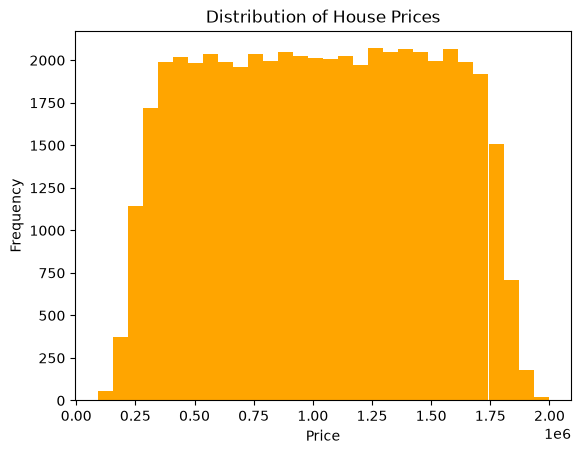

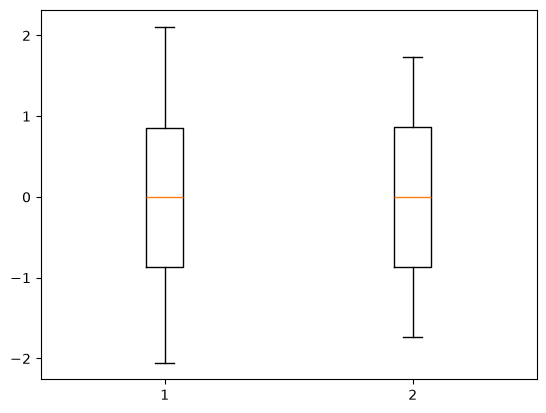

<Axes: >

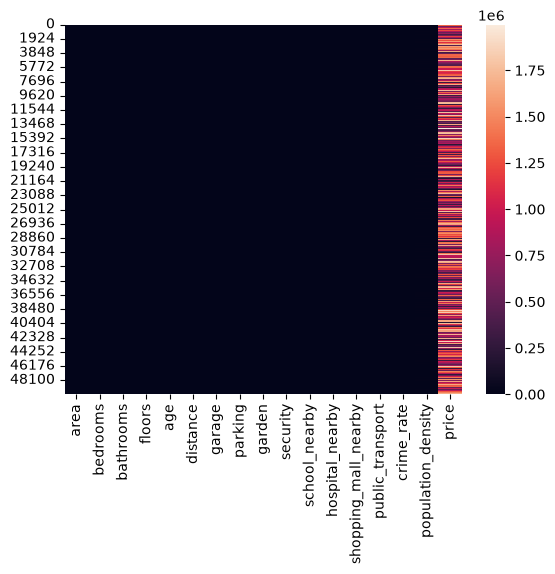

In [16]:
print(house.corr(numeric_only=True))
# Distribution of target

import matplotlib.pyplot as plt

plt.hist(house["price"], bins=30, color='orange')
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Distribution of House Prices")
plt.show()
# Outliers
from sklearn.preprocessing import StandardScaler

std = StandardScaler()
X_scale = std.fit_transform(house[['price','area']])

plt.boxplot(X_scale)
plt.show()
sns.heatmap(house.drop(columns=["location","income_level"]))

3. Data Cleaning

In [17]:
# Missing values

house.isna().sum()

# Duplicate values

house.duplicated().sum()

# Wrong datatypes
house.dtypes


area                      int64
bedrooms                  int64
bathrooms                 int64
floors                    int64
age                       int64
distance                  int64
garage                    int64
parking                   int64
garden                    int64
security                  int64
school_nearby             int64
hospital_nearby           int64
shopping_mall_nearby      int64
public_transport          int64
crime_rate              float64
population_density        int64
location                    str
income_level                str
price                   float64
dtype: object

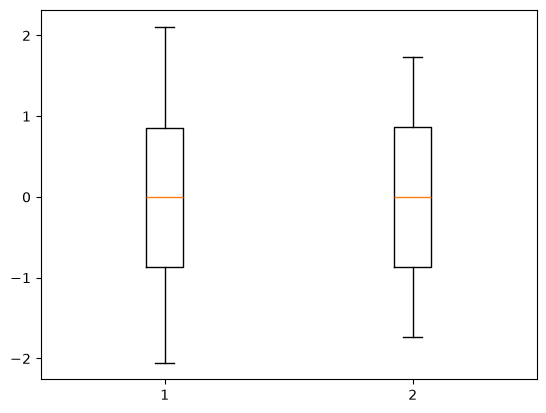

In [18]:
# Outlier treatment (optional)
plt.boxplot(X_scale)
plt.show()

4.Feature Engineering

In [19]:
# Convert categorical columns

# Label Encoding
# One Hot Encoding
# dummies = pd.get_dummies(house[['location','income_level']],drop_first= True, dtype=int)



# house = pd.concat(
#     [house.drop(columns=['location', 'income_level']), dummies],
#     axis=1,
  
# )
# house

In [20]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in ['location', 'income_level']:
    house[col] = le.fit_transform(house[col])

house

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,location,income_level,price
0,1360,6,2,2,9,10,0,0,1,0,1,0,1,0,6.939333,7242,2,1,5.952493e+05
1,4272,5,2,3,24,8,1,0,0,1,1,1,1,0,0.400918,7729,0,1,1.571208e+06
2,3592,1,4,3,4,20,0,1,1,1,0,1,0,1,6.292386,1081,2,2,1.379943e+06
3,966,5,2,2,6,14,1,0,0,0,0,1,1,0,8.964112,8912,1,1,4.367819e+05
4,4926,4,3,1,18,9,0,0,0,0,1,0,1,1,2.843309,8146,0,2,1.792425e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,733,1,4,1,23,23,0,0,1,0,0,1,1,1,1.699633,2188,2,2,3.386262e+05
49996,3420,4,1,3,9,13,1,1,1,0,0,0,1,1,9.451960,7273,0,1,1.185043e+06
49997,2218,3,1,2,3,6,0,1,1,0,1,0,0,1,8.659219,9856,1,2,8.443978e+05
49998,992,2,4,3,26,20,1,0,0,0,0,0,1,0,6.343849,2858,2,1,3.796953e+05


In [21]:
X_scale

array([[-0.94977525, -1.07388234],
       [ 1.18106786,  1.1710649 ],
       [ 0.76347163,  0.64683272],
       ...,
       [-0.40580114, -0.41242467],
       [-1.42040167, -1.35758446],
       [ 0.91705298,  0.79330936]], shape=(50000, 2))

In [22]:
from sklearn.model_selection import train_test_split

X = house.drop(columns=['price'])
y = house['price']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)


In [23]:
X_train.shape

(40000, 18)

In [24]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](18,)","[ 350.06, 11909.46, 9155.12,..., 2.05, 40097.19,-14941.6 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](18,)","['area','bedrooms','bathrooms',...,'population_density','location', 'income_level']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.781e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,18
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(18)


In [25]:
y_pred = lr.predict(X_test)
y_pred

array([ 723033.09332409,  451739.36640136, 1687376.09580449, ...,
       1048996.16059624, 1156915.87781627, 1720398.74230845],
      shape=(10000,))

In [26]:
from sklearn.metrics import r2_score,mean_absolute_error,root_mean_squared_error,mean_squared_error

r2 = r2_score(y_test,y_pred)
print("r2 score = ",r2_score(y_test,y_pred))

print("="*30)
print("mean absolute error = ",mean_absolute_error(y_test,y_pred))
print("="*30)
print('mean squared error ',mean_squared_error(y_test,y_pred))
print("="*30)
print('root mean squared error',root_mean_squared_error(y_test,y_pred))

# Adjusted R²
n = X_train.shape[0]
p = X_train.shape[1]
adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("R²:", r2)
print("Adjusted R²:", adjusted_r2)

r2 score =  0.9968488990272465
mean absolute error =  20692.584282582404
mean squared error  663761366.6440895
root mean squared error 25763.56665223372
R²: 0.9968488990272465
Adjusted R²: 0.9968474803579408
